## PHYLOGENETIC ANALYSIS OF AVIAN INFLUENZA

In [1]:
#Check version of python
!python --version

Python 3.10.12


In [2]:
#installing conda
!pip install --upgrade --force-reinstall zstandard cuda-python
!pip install -q condacolab alv phylo-treetime

!sed -i '/cudatoolkit/d' /usr/local/conda-meta/pinned

#Python code to run the installation
import condacolab
condacolab.install()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.2/24.2 MB 43.9 MB/s eta 0:00:00
  Attempting uninstall: cuda-python
    Found existing installation: cuda-python 12.2.1
    Uninstalling cuda-python-12.2.1:
      Successfully uninstalled cuda-python-12.2.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.4/148.4 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 47.7 MB/s eta 0:00:00
sed: can't read /usr/local/conda-meta/pinned: No such file or directory
⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/23.11.0-0/Mambaforge-23.11.0-0-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:12
🔁 Restarting kernel...


In [1]:
#Installing other libraries
!mamba install -c bioconda mafft iqtree seqkit --quiet

Preparing transaction: ...working... done
Verifying transaction: ...working... done
Executing transaction: ...working... done


## Getting the dataset fasta file to be analyzed.

In [2]:
#Check the header
!head Dataset2.fasta

>A/American_crow/PEI/FAV-0019-01/2022|2022-12-26||EPI_ISL_17494319
AGCAAAAGCAGGGGTTCACTCTGTCAAAATGGAGAACATAGTACTTCTTCTTGCAATAGTTAGCCTTGTTAGAAGTGATCAGATTTGCATTGGTTACCATGCAAACAATTCGACAGAGCAGGTTGACACGATAATGGAAAAGAACGTCACTGTTACACATGCCCAAGACATACTGGAAAAAACACACAACGGGAAGCTCTGTGATTTAAATGGGGTGAAGCCTCTGATTTTAAAGGATTGTAGTGTAGCTGGGTGGCTCCTCGGAAACCCAATGTGCGACGAATTCATCAGAGTGCCGGAATGGTCCTACATAGTGGAGCGGGCTAATCCAGCCAATGACCTCTGTTACCCAGGGAGCCTCAATGACTATGAAGAACTGAAACACCTGTTGAGCAGAATAAATCATTTTGAGAAGATTCTGATCATCCCCAAGAGTTCCTGGCCAAATCATGAAACATCACTAGGGGTGAGCGCAGCTTGTCCATACCAGGGAGCGCCCTCCTTTTTCAGAAATGTGTTGTGGCTTATCAAAAAGAACGATGCATACCCAACAATAAAGATAAGCTACAATAATACCAATCGGGAAGATCTCTTGATACTGTGGGGGATTCATCATTCCAACAATGCAGAAGAGCAGACAAATCTCTATAAAAACCCAACCACCTACATTTCAGTTGGAACATCAACTTTAAACCAGAGGTTGGTACCAAAAATAGCTACTAGATCCCAAGTAAACGGGCAACGTGGAAGAATGGACTTCTTCTGGACAATTTTAAAACCAGATGATACAATCCATTTCGAGAGTAATGGAAATTTCATTGCACCAGAATATGCATATAAAATTGTCAAGAAAGGGGACTCAACAATTATGAAAAGTGGAGTGGAATATGGCCACTGCGACACCAAATGTCAAACCCCAGTAGGAGCGATAAA

In [3]:
#Removing unnecessary fields from data file
with open('Dataset2.fasta', 'r') as infile, open('Dataset2_c.fasta', 'w') as outfile:
        for line in infile:
            if line.startswith('>'):  # Check if the line is a header
                # Remove everything after '||' (including '||')
                modified_line = line.split('||')[0] + '\n'
                outfile.write(modified_line)
            else:
                outfile.write(line)  # Write sequence lines unchanged

In [4]:
#Copying the changes into the main file to be worked on
!seqkit seq -o Dataset2.fasta Dataset2_c.fasta

In [5]:
!head Dataset2.fasta

>A/American_crow/PEI/FAV-0019-01/2022|2022-12-26
AGCAAAAGCAGGGGTTCACTCTGTCAAAATGGAGAACATAGTACTTCTTCTTGCAATAGT
TAGCCTTGTTAGAAGTGATCAGATTTGCATTGGTTACCATGCAAACAATTCGACAGAGCA
GGTTGACACGATAATGGAAAAGAACGTCACTGTTACACATGCCCAAGACATACTGGAAAA
AACACACAACGGGAAGCTCTGTGATTTAAATGGGGTGAAGCCTCTGATTTTAAAGGATTG
TAGTGTAGCTGGGTGGCTCCTCGGAAACCCAATGTGCGACGAATTCATCAGAGTGCCGGA
ATGGTCCTACATAGTGGAGCGGGCTAATCCAGCCAATGACCTCTGTTACCCAGGGAGCCT
CAATGACTATGAAGAACTGAAACACCTGTTGAGCAGAATAAATCATTTTGAGAAGATTCT
GATCATCCCCAAGAGTTCCTGGCCAAATCATGAAACATCACTAGGGGTGAGCGCAGCTTG
TCCATACCAGGGAGCGCCCTCCTTTTTCAGAAATGTGTTGTGGCTTATCAAAAAGAACGA


In [6]:
# How many sequences in the dataset
!grep -c '>' Dataset2.fasta

64


In [7]:
# Use seqkit to get statistics
!seqkit stats --all Dataset2.fasta

file            format  type  num_seqs  sum_len  min_len  avg_len  max_len     Q1     Q2     Q3  sum_gap    N50  N50_num  Q20(%)  Q30(%)  AvgQual  GC(%)
Dataset2.fasta  FASTA   DNA         64  113,606    1,761  1,775.1    1,776  1,776  1,776  1,776        0  1,776        1       0       0        0  41.82


### Parse the fasta file


In [8]:
input_file = "Dataset2.fasta"

sequences = {}

def read_fasta(input_file):
  sequences = {}
  with open(input_file, "r") as f:
        for line in f:
            if line.startswith(">"):
                header = line.strip()[1:]
                sequences[header] = ""
            else:
                sequences[header] += line.strip()
  return sequences

sequences = read_fasta("Dataset2.fasta")
print("Number of sequences: ", len(sequences))
print("Min length ", min(len(seq) for seq in sequences.values()))
print("Max length ", max(len(seq) for seq in sequences.values()))
print("Average length ", sum(len(seq) for seq in sequences.values())/len(sequences))

Number of sequences:  64
Min length  1761
Max length  1776
Average length  1775.09375


### Filter low quality sequences

Any ambiguous nucleotides will be removed.

In [10]:
from collections import Counter
with open("sequence_to_filter.txt", "w") as f:
  for header, sequence in sequences.items():
      count = sum(sequence.count(char) for char in "WSKMYRVHDBN")
      # Sequences with > 10% ambiguous nucleotides
      if count / len(sequence) > 0.1:
          print(f"Removing {header}: {count} ambiguous nucleotides")
          f.write(header + "\n")

# Filter selected sequences
!seqkit grep -v -f sequence_to_filter.txt Dataset2.fasta > Dataset2.filtered.fasta && cp Dataset2.filtered.fasta Dataset2.fasta

[WARN] 0 patterns loaded from file


## Alignment using MAFFT

In [11]:
!mafft --thread -1 --auto Dataset2.fasta > Dataset2.aligned.fasta && cp Dataset2.aligned.fasta Dataset2.aln

OS = linux
The number of physical cores =  1
outputhat23=16
treein = 0
compacttree = 0
stacksize: 8192 kb
generating a scoring matrix for nucleotide (dist=200) ... done
All-to-all alignment.
tbfast-pair (nuc) Version 7.525
alg=L, model=DNA200 (2), 2.00 (6.00), -0.10 (-0.30), noshift, amax=0.0
1 thread(s)

outputhat23=16
Loading 'hat3.seed' ... 
done.
Writing hat3 for iterative refinement
generating a scoring matrix for nucleotide (dist=200) ... done
Gap Penalty = -1.53, +0.00, +0.00
tbutree = 1, compacttree = 0
Constructing a UPGMA tree ... 
   60 / 64
done.

Progressive alignment ... 
STEP    63 /63 (thread    0) 
done.
tbfast (nuc) Version 7.525
alg=A, model=DNA200 (2), 1.53 (4.59), -0.00 (-0.00), noshift, amax=0.0
1 thread(s)

minimumweight = 0.000010
autosubalignment = 0.000000
nthread = 1
randomseed = 0
blosum 62 / kimura 200
poffset = 0
niter = 16
sueff_global = 0.100000
nadd = 16
Loading 'hat3' ... done.
generating a scoring matrix for nucleotide (dist=200) ... done

   60 / 64


#### MAFFT OUTPUT


In [13]:
!head Dataset2.aln

>A/American_crow/PEI/FAV-0019-01/2022|2022-12-26
agcaaaagcaggggttcactctgtcaaaatggagaacatagtacttcttcttgcaatagt
tagccttgttagaagtgatcagatttgcattggttaccatgcaaacaattcgacagagca
ggttgacacgataatggaaaagaacgtcactgttacacatgcccaagacatactggaaaa
aacacacaacgggaagctctgtgatttaaatggggtgaagcctctgattttaaaggattg
tagtgtagctgggtggctcctcggaaacccaatgtgcgacgaattcatcagagtgccgga
atggtcctacatagtggagcgggctaatccagccaatgacctctgttacccagggagcct
caatgactatgaagaactgaaacacctgttgagcagaataaatcattttgagaagattct
gatcatccccaagagttcctggccaaatcatgaaacatcactaggggtgagcgcagcttg
tccataccagggagcgccctcctttttcagaaatgtgttgtggcttatcaaaaagaacga


In [14]:
!seqkit stats Dataset2.aln

file          format  type  num_seqs  sum_len  min_len  avg_len  max_len
Dataset2.aln  FASTA   DNA         64  113,664    1,776    1,776    1,776


### Inspecting the alignment

The complete sequence of a hemagglutinin (HA) gene of a recent human influenza A strain, A/Victoria/3/75, is 1768 nucleotides long and contains the information for 567 amino acids.

In [19]:
# Inspecting alignment using alv- start of alignment
!alv -sa 0 100 -as 0 20 -w 1000 Dataset2.aln

A/American_crow/PEI/ agcaaaagcaggggttcactctgtcaaaatggagaacatagtacttcttcttgcaatagttagccttgttagaagtgatcagatttgcattggttaccat
A/barnacle_goose/Eng agcaaaagcaggggttcactctgtcaaaatggagaacatagtacttcttcttgcaacagttagccttgttaaaagtgatcagatttgcattggttaccat
A/barnacle_goose/Sco agcaaaagcaggggttcactctgtcaaaatggagaacatagtacttcttcttgcaacagttagccttgttaaaagtgatcagatttgcattggttaccat
A/Barnacle_goose/Sco agcaaaagcaggggttcactctgtcaaaatggagaacatagtacttcttcttgcaacagttagccttgttaaaagtgatcagatttgcattggttaccat
A/Barnacle_goose/Sco agcaaaagcaggggttcactctgtcaaaatggagaacatagtacttcttcttgcaacagttagccttgttaaaagtgatcagatttgcattggttaccat
A/Barnacle_goose/Sco agcaaaagcaggggttcactctgtcaaaatggagaacatagtacttcttcttgcaacagttagccttgttaaaagtgatcagatttgcattggttaccat
A/barnacle_goose/Swe agcaaaagcaggggttcactctgtcaaaatggagaacatagtacttcttcttgcaacagttagccttgttaaaagtgatcagatttgcattggttaccat
A/Black-headed_gull/ -gcaaaagcaggggttcactctgtcaaaatggagaacatagtacttcttcttgcaatagttagccttgttagaagtgatcagatttgcattggttaccat
A/chicken/England/00 agc

In [35]:
# # Inspecting alignment using alv- end of alignment
!alv -sa 1700 1800 -as 0 20 -w 1000 Dataset2.aln

A/American_crow/PEI/ atgggtcgttacagtgcagaatttgcatttagatttgtgagctcagattgtagttaaaaacacccttgtttctact
A/barnacle_goose/Eng atgggtcgttacagtgcagaatttgcatttagatttgtgagctcagattgtagttaaaaacacccttgtttctact
A/barnacle_goose/Sco atgggtcgttacagtgcagaatttgcatttagatttgtgagctcagattgtagttaaaaacacccttgtttctact
A/Barnacle_goose/Sco atgggtcgttacagtgcagaatttgcatttagatttgtgagctcagattgtagttaaaaacacccttgtttctact
A/Barnacle_goose/Sco atgggtcgttacagtgcagaatttgcatttagatttgtgagctcagattgtagttaaaaacacccttgtttctact
A/Barnacle_goose/Sco atgggtcgttacagtgcagaatttgcatttagatttgtgagctcagattgtagttaaaaacacccttgtttctact
A/barnacle_goose/Swe atgggtcgttacagtgcagaatttgcatttagatttgtgagctcagattgtagttaaaaacacccttgtttctact
A/Black-headed_gull/ atgggtcgttacagtgcagaatttgcatttagatttgtgagctcagattgtagttaaaaacacccttgtttctact
A/chicken/England/00 atgggtcgttacagtgcagaatttgcatttagatttgtgagctcagattgtagttaaaaacacccttgtttctact
A/chicken/England/06 atgggtcgttacagtgcagaatttgcatttagatttgtgagctcagattgtagttaaaaacacccttgtttctact
A/chicken/England/06

### Filter and trim the aligment
Trim the ends of the aligment (error prone) using the first sequence as a guide.

In [36]:
!seqkit head -n 1 Dataset2.aln | seqkit locate -Pdip '(N)' | head -n2 # find the first base i.e. not a gap
!seqkit head -n 1 Dataset2.aln | seqkit locate -Pdip '(N)' | tail -n1 # find the last base i.e. not a gap

seqID	patternName	pattern	strand	start	end	matched
A/American_crow/PEI/FAV-0019-01/2022|2022-12-26	(N)	(N)	+	1	1	a
A/American_crow/PEI/FAV-0019-01/2022|2022-12-26	(N)	(N)	+	1776	1776	t


In [37]:
start, *_ = !seqkit head -n 1 Dataset2.aln | seqkit locate -Pdip '(N)' | sed -n '2p' | awk '{print $5}'
end, *_ = !seqkit head -n 1 Dataset2.aln | seqkit locate -Pdip '(N)' | sed -n '$p' | awk '{print $5}'
!seqkit -w 0 subseq -r $start:$end Dataset2.aln > Dataset2.trimmed.aln && cp Dataset2.trimmed.aln Dataset2.aln

[INFO] create or read FASTA index ...
[INFO] create FASTA index for Dataset2.aln
[INFO]   64 records loaded from Dataset2.aln.seqkit.fai


In [18]:
#using Biopython removing the sequences with alot of differences
from Bio import AlignIO
from Bio import SeqIO
from Bio.SeqRecord import SeqRecord

# Load the MSA file
alignment = AlignIO.read("Dataset2.aln", "fasta")

# Select the first sequence as the reference
reference_seq = alignment[0].seq

# Define a similarity threshold (e.g., 90%)
threshold = 0.6

def calculate_similarity(seq1, seq2):
    """Calculate the similarity score between two sequences."""
    matches = sum(res1 == res2 for res1, res2 in zip(seq1, seq2))
    return matches / len(seq1)

# Filter sequences
filtered_sequences = []
for record in alignment:
    similarity = calculate_similarity(reference_seq, record.seq)
    if similarity >= threshold:
        filtered_sequences.append(record)
    else:
        print(f"Removing sequence {record.id} with similarity {similarity:.2f}")

# Save the filtered sequences to a new FASTA file
with open("Dataset2.clean.aln", "w") as output_handle:
    SeqIO.write(filtered_sequences, output_handle, "fasta")

In [19]:
#confirm the filter results
!seqkit stats Dataset2.clean.aln

file                format  type  num_seqs  sum_len  min_len  avg_len  max_len
Dataset2.clean.aln  FASTA   DNA         64  113,664    1,776    1,776    1,776


### Realign the sequences using MAFFT after changes

In [38]:
!mafft --thread -1 --auto Dataset2.clean.aln > Dataset2.realigned.aln && cp Dataset2.realigned.aln Dataset2.aln

/usr/local/bin/mafft: Cannot open Dataset2.clean.aln.

OS = linux
The number of physical cores =  1
/usr/local/bin/mafft: line 1291: /tmp/mafft.UP8rKlLI70/infile: No such file or directory
awk: fatal: cannot open file `/tmp/mafft.UP8rKlLI70/size' for reading: No such file or directory
awk: fatal: cannot open file `/tmp/mafft.UP8rKlLI70/size' for reading: No such file or directory
/usr/local/bin/mafft: line 1295: [: too many arguments
/usr/local/bin/mafft: line 1300: [: too many arguments
/usr/local/bin/mafft: line 1305: [: too many arguments
/usr/local/bin/mafft: line 1310: [: -lt: unary operator expected
/usr/local/bin/mafft: line 1315: [: -lt: unary operator expected
/usr/local/bin/mafft: line 1322: [: -lt: unary operator expected
/usr/local/bin/mafft: line 1329: [: -lt: unary operator expected
------------------------------------------------------------------------------
  MAFFT v7.525 (2024/Mar/13)
  https://mafft.cbrc.jp/alignment/software/
  MBE 30:772-780 (2013), NAR 30:3059-306

In [39]:
!seqkit stats --all Dataset2.aln

file          format  type  num_seqs  sum_len  min_len  avg_len  max_len     Q1     Q2     Q3  sum_gap    N50  N50_num  Q20(%)  Q30(%)  AvgQual  GC(%)
Dataset2.aln  FASTA   DNA         64  113,664    1,776    1,776    1,776  1,776  1,776  1,776       58  1,776        1       0       0        0   41.8


## Phylogenetic Inference

Using IQ-TREE for maximum likelihood phylogenetic analyses of the sequences. ModeFinder- builtin program will evaluate substitution model best suited to data
When the process is complete, output files: treefile, consensus ML tree, IQTree analysis report and log file is generated.

In [40]:
!iqtree -s Dataset2.aln -m TEST -B 1000

IQ-TREE multicore version 2.3.6 for Linux x86 64-bit built Aug  4 2024
Developed by Bui Quang Minh, Nguyen Lam Tung, Olga Chernomor, Heiko Schmidt,
Dominik Schrempf, Michael Woodhams, Ly Trong Nhan, Thomas Wong

Host:    d78bf134abc7 (AVX2, FMA3, 12 GB RAM)
Command: iqtree -s Dataset2.aln -m TEST -B 1000
Seed:    327563 (Using SPRNG - Scalable Parallel Random Number Generator)
Time:    Thu Oct 24 23:21:44 2024
Kernel:  AVX+FMA - 1 threads (2 CPU cores detected)

HINT: Use -nt option to specify number of threads because your CPU has 2 cores!
HINT: -nt AUTO will automatically determine the best number of threads to use.

Reading alignment file Dataset2.aln ... Fasta format detected
Reading fasta file: done in 0.0034014 secs using 61.27% CPU
Alignment most likely contains DNA/RNA sequences
Alignment has 64 sequences with 1776 columns, 88 distinct patterns
34 parsimony-informative, 44 singleton sites, 1698 constant sites
                                                                     

In [41]:
#Viewing trees in newick format
!cat Dataset2.aln.iqtree

IQ-TREE 2.3.6 built Aug  4 2024

Input file name: Dataset2.aln
Type of analysis: ModelFinder + tree reconstruction + ultrafast bootstrap (1000 replicates)
Random seed number: 327563

REFERENCES
----------

To cite IQ-TREE please use:

Bui Quang Minh, Heiko A. Schmidt, Olga Chernomor, Dominik Schrempf,
Michael D. Woodhams, Arndt von Haeseler, and Robert Lanfear (2020)
IQ-TREE 2: New models and efficient methods for phylogenetic inference
in the genomic era. Mol. Biol. Evol., in press.
https://doi.org/10.1093/molbev/msaa015

To cite ModelFinder please use: 

Subha Kalyaanamoorthy, Bui Quang Minh, Thomas KF Wong, Arndt von Haeseler,
and Lars S Jermiin (2017) ModelFinder: Fast model selection for
accurate phylogenetic estimates. Nature Methods, 14:587–589.
https://doi.org/10.1038/nmeth.4285

Since you used ultrafast bootstrap (UFBoot) please also cite: 

Diep Thi Hoang, Olga Chernomor, Arndt von Haeseler, Bui Quang Minh,
and Le Sy Vinh (2018) UFBoot2: Improving the ultrafast bootstrap
appr

In [42]:
#Viewing trees in newick format
!cat Dataset2.aln.treefile

(A/American_crow/PEI/FAV-0019-01/2022|2022-12-26:0.0000010000,((((((((((A/barnacle_goose/England/293809/2021|2021-11-26:0.0000010000,A/Barnacle_goose/Scotland/109090/2021|2021-12-17:0.0000010000)96:0.0005634861,A/barnacle_goose/Scotland/062003/2021|2021-11-19:0.0005634861)52:0.0000010000,A/chicken/Scotland/064936/2021|2021-12-02:0.0005634861)91:0.0005634861,((((A/Barnacle_goose/Scotland/058494/2021|2021-11-16:0.0000010000,A/pink_footed_goose/Scotland/058488/2021|2021-11-16:0.0000010000)92:0.0005634861,(A/Kestrel/Scotland/058512/2021|2021-11-16:0.0005634861,A/Whooper_swan/Scotland/072171/2021|2021-12-11:0.0000010000)91:0.0005634861)15:0.0000010000,((A/Barnacle_goose/Scotland/072152/2021|2021-12-13:0.0005634861,(((A/chicken/Northern_Ireland/17903/2021|2021-12-09:0.0011278195,A/greylag_goose/Northern_Ireland/17795/2021|2021-12-08:0.0005634861)19:0.0000010000,(A/Common_buzzard/Scotland/073099/2021|2021-12-15:0.0000010000,((A/Greylag_goose/Isle_of_Man/010298/2022|2022-01-14:0.0005647710,A/m

## Root to tip regression



In [44]:
!sed 's/1905-07-14/2022-02-14/g' Dataset2.aln > Dataset2.date.fixed.aln && cp Dataset2.date.fixed.aln Dataset2.aln
!sed 's/1905-07-14/2022-02-14/g' Dataset2.aln.treefile > Dataset2.date.fixed.treefile && cp Dataset2.date.fixed.treefile Dataset2.aln.treefile

## Creating a Time Tree (Chronogram)

Using TreeTime to create a lineage tree and infering molecular clock phylogenies.

In [45]:
with open("Dataset2.metadata", "w") as f:
  f.write("name,date\n")
  for line in open("Dataset2.aln"):
    if not line.startswith(">"):
      continue
    header = line.strip()[1:]
    f.write(f"{header},{header.split('|')[-1]}\n")

In [46]:
!treetime --tree Dataset2.aln.treefile --dates Dataset2.metadata --aln Dataset2.aln --outdir timetree


Attempting to parse dates...
	Using column 'name' as name. This needs match the taxon names in the tree!!
	Using column 'date' as date.

0.00	-TreeAnc: set-up

0.47	TreeTime.reroot: with method or node: least-squares

0.47	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

0.65	TreeTime.reroot: with method or node: least-squares

0.65	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

1.04	###TreeTime.run: INITIAL ROUND

2.52	TreeTime.reroot: with method or node: least-squares

2.52	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

2.71	###TreeTime.run: rerunning timetree after rerooting

4.37	###TreeTime.run: ITERATION 1 out of 2 iterations

4.37	DEPRECATION WARNING. TreeTime.resolve_polytomies: You are resolving
    	polytomies using the old 'greedy' mode. This is not well suited for large
    	polytomies. Stochastic resolution will become the default in future
    	versions. To switch now, rerun with the flag `--stocha

Try downloading and opening a few of the output files. There are visulisation as well as

tree as
	 timetree/timetree.pdf

--- root-to-tip plot saved to  
	timetree/root_to_tip_regression.pdf

--- alignment including ancestral nodes saved as  
	 timetree/ancestral_sequences.fasta

--- saved divergence times in
	 timetree/dates.tsv

--- tree saved in nexus format as  
	 timetree/timetree.nexus

--- tree saved in auspice json format as  
	 timetree/auspice_tree.json

--- divergence tree saved in nexus format as  
	 timetree/divergence_tree.nexus

--- saved detected outliers as timetree/outliers.tsv

Q: what is the TMRCA? Is it what you expect?

## Tree visualisation

Using library ggtree to display the tree.

In [52]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [53]:
%%R

if (!requireNamespace("BiocManager", quietly = TRUE)) {
    install.packages("BiocManager")
    }
if (system.file(package = "ggtree") == '') {
        BiocManager::install("ggtree",quiet = TRUE)
    }
if (system.file(package = "treeio") == '') {
        BiocManager::install("treeio",quiet = TRUE)
    }

install.packages("ggnewscale")

R[write to console]: Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

R[write to console]: trying URL 'https://cran.rstudio.com/src/contrib/ggnewscale_0.5.0.tar.gz'

R[write to console]: Content type 'application/x-gzip'
R[write to console]:  length 411919 bytes (402 KB)

R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[w

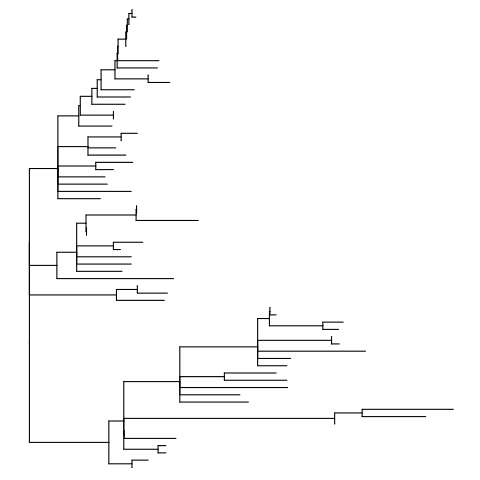

In [54]:
%%R
library(ggtree)
library(treeio)

tree <- read.nexus("/content/timetree/timetree.nexus")
ggtree(tree)

### Using country CSV to analyse data in different countries and regions and their occurence.



In [57]:
!head country.csv

name,country,region
A/American_crow/PEI/FAV-0019-01/2022|2022-12-26,Canada,North America
A/barnacle_goose/England/293809/2021|2021-11-26,UK,Europe
A/barnacle_goose/Scotland/062003/2021|2021-11-19,UK,Europe
A/Barnacle_goose/Scotland/058494/2021|2021-11-16,UK,Europe
A/Barnacle_goose/Scotland/072152/2021|2021-12-13,UK,Europe
A/Barnacle_goose/Scotland/109090/2021|2021-12-17,UK,Europe
A/barnacle_goose/Sweden/SVA211216SZ0382/FB004836/2021|2021-12-09,Europe,other
A/Black-headed_gull/England/064433/2021|2021-11-30,UK,Europe
A/chicken/England/007584/2022|2022-01-23,UK,Europe


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


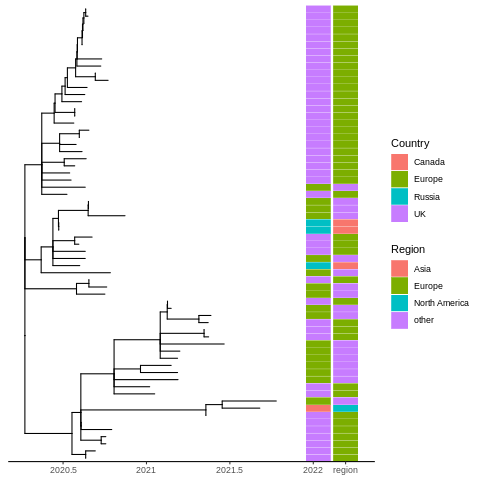

In [58]:
%%R
# Load libraries
library(ggtree)
library(ape)
library(dplyr)

library(ggnewscale)

# Load the tree and metadata
tree <- read.nexus("/content/timetree/timetree.nexus")
metadata <- read.csv("country.csv")

# Rename 'name' column in metadata to 'label' to match tree tip labels
metadata <- metadata %>% rename(label = name)

# Create a tree plot
p <- ggtree(tree, mrsd="2021-10-12") +
  theme_tree2()

# Convert metadata to a format suitable for gheatmap (rownames = tip labels)
rownames(metadata) <- metadata$label
metadata <- metadata %>% select(-label)  # Remove label column since it's now rownames

# Create a heatmap next to the tree
p_heatmap <- gheatmap(p, metadata %>% select(country), width = 0.1, offset=.1, colnames = FALSE, colnames_offset_y = .25, legend_title = "Country") +
  scale_x_ggtree() +
  new_scale_fill()

p_heatmap <- gheatmap(p_heatmap, metadata %>% select(region), width = 0.1, offset=.265, colnames = FALSE, colnames_offset_y = .25, legend_title = "Region") +
  scale_x_ggtree()

# Display the plot with heatmap
p_heatmap


In [59]:
!treetime --tree Dataset2.aln.treefile --dates Dataset2.metadata --aln Dataset2.aln --outdir timetree-confidence --confidence --covariation


Attempting to parse dates...
	Using column 'name' as name. This needs match the taxon names in the tree!!
	Using column 'date' as date.

0.00	-TreeAnc: set-up

0.41	TreeTime.reroot: with method or node: least-squares

0.41	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

0.60	TreeTime.reroot: with method or node: least-squares

0.60	TreeTime.reroot: rerooting will account for covariance and shared ancestry.

1.03	###TreeTime.run: INITIAL ROUND

2.76	TreeTime.reroot: with method or node: least-squares

2.76	TreeTime.reroot: rerooting will account for covariance and shared ancestry.

3.18	###TreeTime.run: rerunning timetree after rerooting

5.81	###TreeTime.run: ITERATION 1 out of 2 iterations

5.81	DEPRECATION WARNING. TreeTime.resolve_polytomies: You are resolving
    	polytomies using the old 'greedy' mode. This is not well suited for large
    	polytomies. Stochastic resolution will become the default in future
    	versions. To switch now, rerun with the flag

## Download all output



In [60]:
!zip -r BINF90004-phylo.zip .

from google.colab import files
files.download("BINF90004-phylo.zip")

  adding: .config/ (stored 0%)
  adding: .config/gce (stored 0%)
  adding: .config/default_configs.db (deflated 98%)
  adding: .config/logs/ (stored 0%)
  adding: .config/logs/2024.10.23/ (stored 0%)
  adding: .config/logs/2024.10.23/13.20.37.094878.log (deflated 93%)
  adding: .config/logs/2024.10.23/13.21.27.810721.log (deflated 56%)
  adding: .config/logs/2024.10.23/13.21.27.081388.log (deflated 57%)
  adding: .config/logs/2024.10.23/13.21.12.657325.log (deflated 85%)
  adding: .config/logs/2024.10.23/13.21.13.932296.log (deflated 58%)
  adding: .config/logs/2024.10.23/13.20.59.252271.log (deflated 58%)
  adding: .config/.last_opt_in_prompt.yaml (stored 0%)
  adding: .config/.last_survey_prompt.yaml (stored 0%)
  adding: .config/.last_update_check.json (deflated 24%)
  adding: .config/active_config (stored 0%)
  adding: .config/configurations/ (stored 0%)
  adding: .config/configurations/config_default (deflated 15%)
  adding: .config/hidden_gcloud_config_universe_descriptor_data_ca

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>